In [32]:
# CodeAlpha Task 2 - Exploratory Data Analysis
# IBM HR Analytics Employee Attrition & Performance Dataset

print("Employee Attrition EDA - CodeAlpha Task 2")

Employee Attrition EDA - CodeAlpha Task 2


# Employee Attrition — Exploratory Data Analysis

## Project Overview

This project performs Exploratory Data Analysis (EDA) on the IBM HR Analytics Employee Attrition & Performance dataset.

The objective is to understand employee characteristics, identify patterns associated with employee attrition, detect potential anomalies and data-quality issues, and validate selected assumptions using statistical analysis and visualization.

## Objectives

- Understand the structure and characteristics of the dataset.
- Explore employee demographics, job-related factors, income and satisfaction.
- Identify patterns associated with employee attrition.
- Detect missing values, duplicate records and potential outliers.
- Examine relationships between important variables.
- Test selected hypotheses using statistical methods.
- Summarize key findings and potential areas for further analysis.

## Key Questions

Before analyzing the data, we will investigate the following questions:

1. What is the overall employee attrition rate?
2. How is attrition distributed across different age groups?
3. Is there a difference in attrition between employees who work overtime and those who do not?
4. Does monthly income differ between employees who stayed and those who left?
5. Which job roles have higher levels of employee attrition?
6. Does job satisfaction appear to be associated with attrition?
7. Does the number of years an employee has worked at the company relate to attrition?
8. Is there a relationship between employee age and monthly income?
9. Are there potential outliers in variables such as age, monthly income and years at the company?
10. Are there missing values, duplicate records or other data-quality issues?

step 4- Import libraries

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Plot settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [34]:
# Load the employee attrition dataset
df = pd.read_csv("employee_attrition.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [35]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1470
Number of columns: 35


In [36]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


Step 5 — Understand the Dataset Structure.

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [38]:
print("Total number of variables:", len(df.columns))
print("\nVariables in the dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Total number of variables: 35

Variables in the dataset:

1. Age
2. Attrition
3. BusinessTravel
4. DailyRate
5. Department
6. DistanceFromHome
7. Education
8. EducationField
9. EmployeeCount
10. EmployeeNumber
11. EnvironmentSatisfaction
12. Gender
13. HourlyRate
14. JobInvolvement
15. JobLevel
16. JobRole
17. JobSatisfaction
18. MaritalStatus
19. MonthlyIncome
20. MonthlyRate
21. NumCompaniesWorked
22. Over18
23. OverTime
24. PercentSalaryHike
25. PerformanceRating
26. RelationshipSatisfaction
27. StandardHours
28. StockOptionLevel
29. TotalWorkingYears
30. TrainingTimesLastYear
31. WorkLifeBalance
32. YearsAtCompany
33. YearsInCurrentRole
34. YearsSinceLastPromotion
35. YearsWithCurrManager


In [39]:
df.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

In [40]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include=["object", "str"]).columns.tolist()

print("Numerical variables:", len(numerical_columns))
print(numerical_columns)

print("\nCategorical variables:", len(categorical_columns))
print(categorical_columns)

Numerical variables: 26
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical variables: 9
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


Step 6 — Data Quality Checks

In [41]:
# Check the number of missing values in each column
missing_values = df.isnull().sum()

# Display missing values for each column
print("Missing values in each column:")
print(missing_values)

# Calculate and display the total number of missing values
print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCu

In [42]:
# Check for duplicate rows in the dataset
duplicate_count = df.duplicated().sum()

# Display the total number of duplicate rows
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [43]:
# Count the number of unique values in each column
unique_counts = df.nunique().sort_values()

# Display the unique value count for each column
print("Number of unique values in each column:")
print(unique_counts)

Number of unique values in each column:
EmployeeCount                  1
Over18                         1
StandardHours                  1
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age

In [44]:
# Identify columns that contain only one unique value
constant_columns = [
    column for column in df.columns
    if df[column].nunique() <= 1
]

# Display the constant columns
print("Constant columns:")
print(constant_columns)

# Display the total number of constant columns
print("\nNumber of constant columns:", len(constant_columns))

Constant columns:
['EmployeeCount', 'Over18', 'StandardHours']

Number of constant columns: 3


In [45]:
# Generate descriptive statistics for all numerical variables
# This helps identify unusual ranges and potential outliers
numerical_summary = df[numerical_columns].describe().T

# Display the statistical summary
numerical_summary

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


Step 7 — Descriptive Statistics

In [47]:
# descriptive statistics for all numerical variables
# This includes count, mean, standard deviation, minimum,
# quartiles, and maximum values

df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [48]:
# Generate a more readable statistical summary
# Each numerical variable is displayed as a separate row

df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [49]:
# Generate descriptive statistics for categorical variables
# This shows the number of unique values, most frequent value,
# and its frequency

df[categorical_columns].describe().T

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


In [50]:
# Count the number of employees in each attrition category
attrition_counts = df["Attrition"].value_counts()

# Display the counts
print("Employee Attrition Distribution:")
print(attrition_counts)

Employee Attrition Distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [51]:
# Calculate the percentage of employees who left the company
attrition_rate = (df["Attrition"] == "Yes").mean() * 100

# Display the attrition rate
print(f"Overall Attrition Rate: {attrition_rate:.2f}%")

Overall Attrition Rate: 16.12%


Step 8 — Univariate Analysis

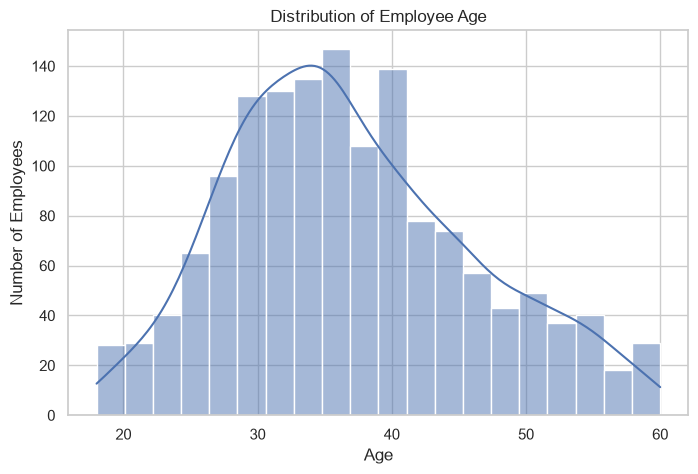

In [52]:
# Plot the distribution of employee ages
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

# Add chart title and labels
plt.title("Distribution of Employee Age")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

# Display the chart
plt.show()

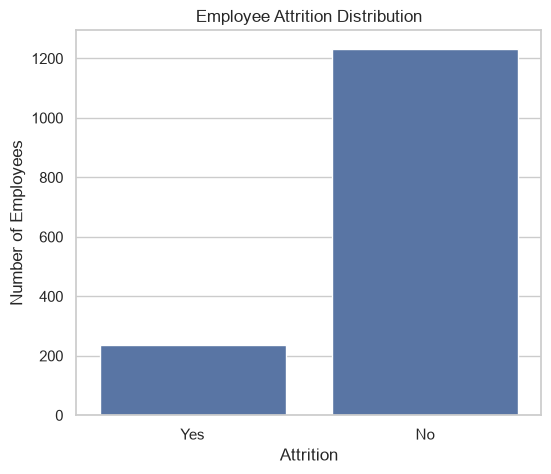

In [53]:
# Count employees based on their attrition status
plt.figure(figsize=(6, 5))

sns.countplot(data=df, x="Attrition")

# Add chart title and labels
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

# Display the chart
plt.show()

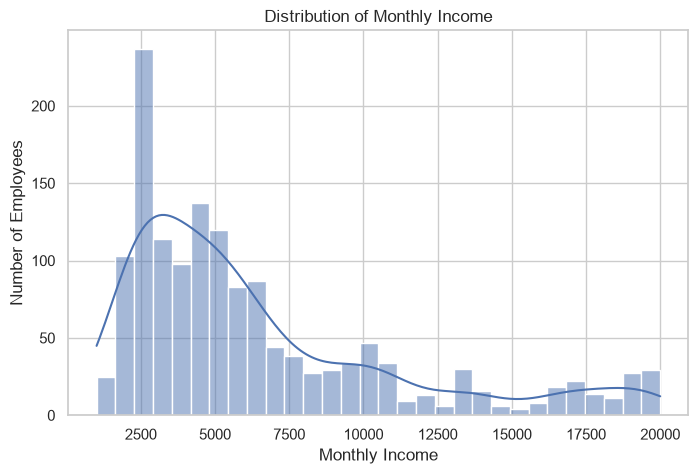

In [54]:
# Plot the distribution of monthly income
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="MonthlyIncome", bins=30, kde=True)

# Add chart title and labels
plt.title("Distribution of Monthly Income")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Employees")

# Display the chart
plt.show()

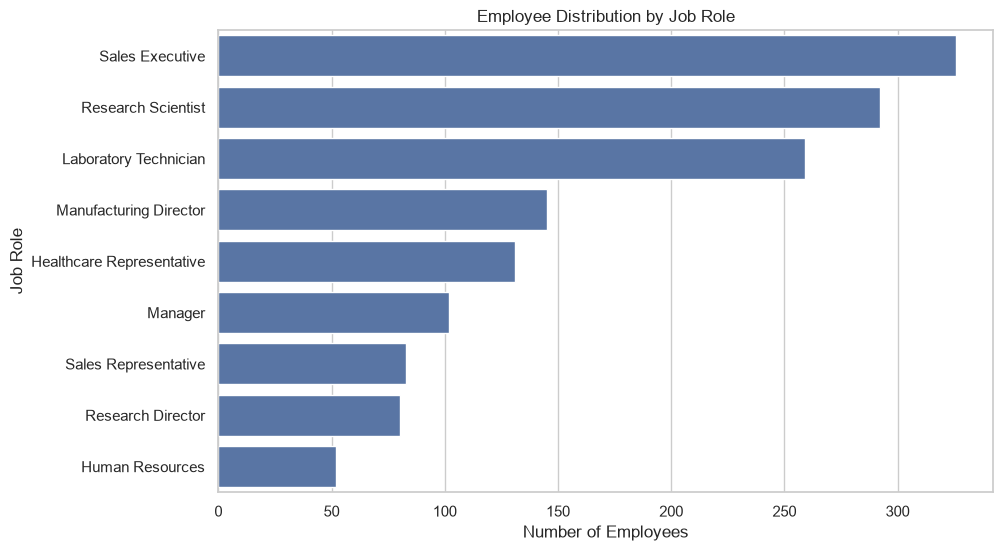

In [55]:
# Count employees in each job role
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="JobRole",
    order=df["JobRole"].value_counts().index
)

# Add chart title and labels
plt.title("Employee Distribution by Job Role")
plt.xlabel("Number of Employees")
plt.ylabel("Job Role")

# Display the chart
plt.show()

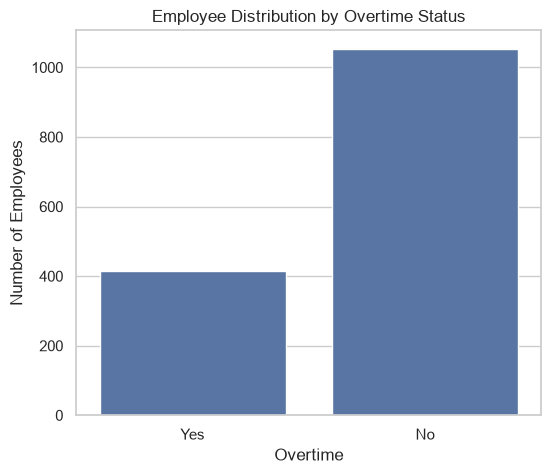

In [56]:
# Count employees based on whether they work overtime
plt.figure(figsize=(6, 5))

sns.countplot(data=df, x="OverTime")

# Add chart title and labels
plt.title("Employee Distribution by Overtime Status")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

# Display the chart
plt.show()

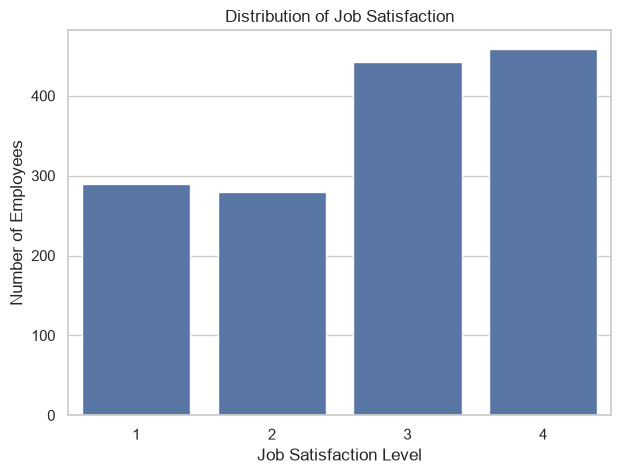

In [57]:
# Count employees according to their job satisfaction level
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="JobSatisfaction")

# Add chart title and labels
plt.title("Distribution of Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Number of Employees")

# Display the chart
plt.show()

Step 9 — Bivariate Analysis

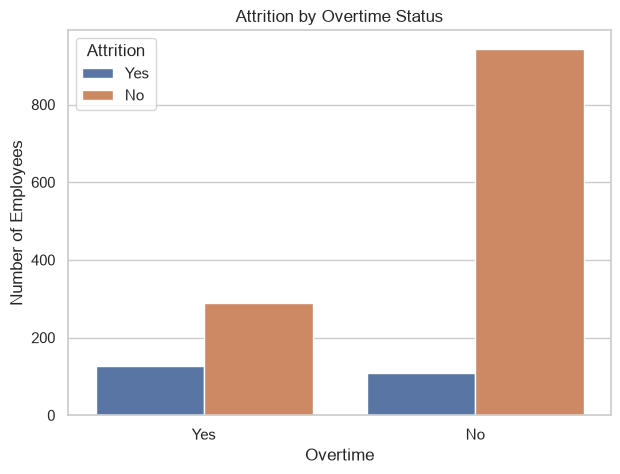

In [58]:
# Compare employee attrition based on overtime status
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="OverTime", hue="Attrition")

# Add chart title and labels
plt.title("Attrition by Overtime Status")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

# Display the chart
plt.show()

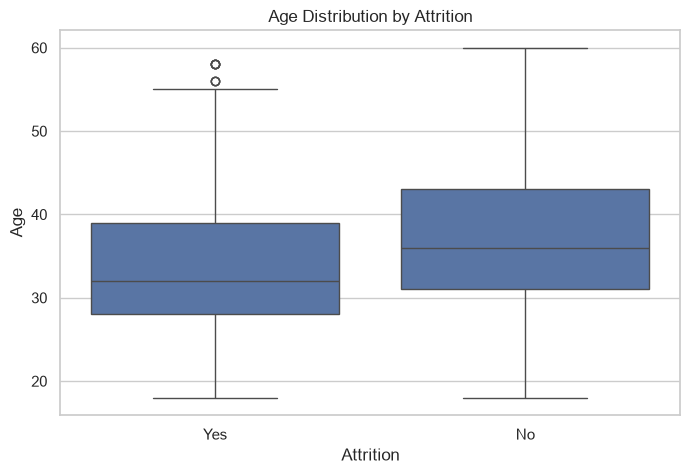

In [59]:
# Compare the age distribution of employees who stayed and left
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Attrition", y="Age")

# Add chart title and labels
plt.title("Age Distribution by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Age")

# Display the chart
plt.show()

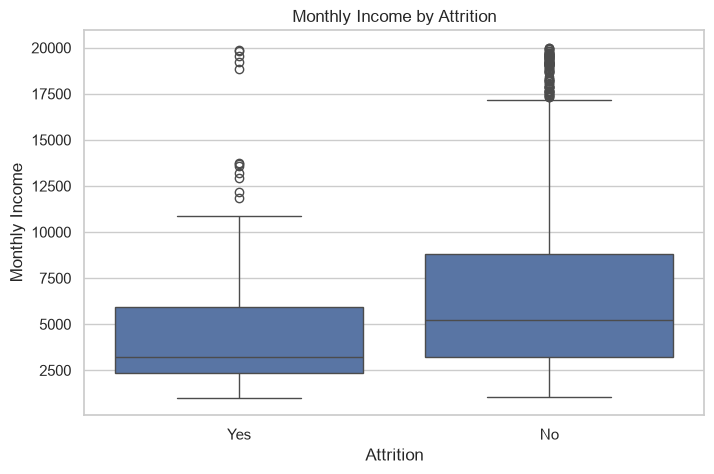

In [60]:
# Compare monthly income between employees who stayed and left
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")

# Add chart title and labels
plt.title("Monthly Income by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

# Display the chart
plt.show()

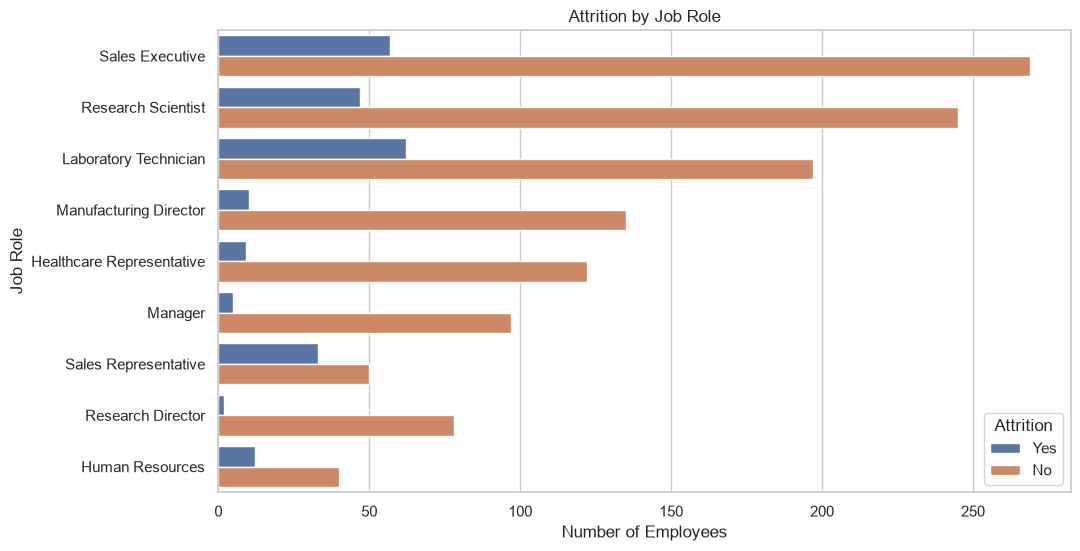

In [61]:
# Compare attrition across different job roles
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    y="JobRole",
    hue="Attrition",
    order=df["JobRole"].value_counts().index
)

# Add chart title and labels
plt.title("Attrition by Job Role")
plt.xlabel("Number of Employees")
plt.ylabel("Job Role")

# Display the chart
plt.show()

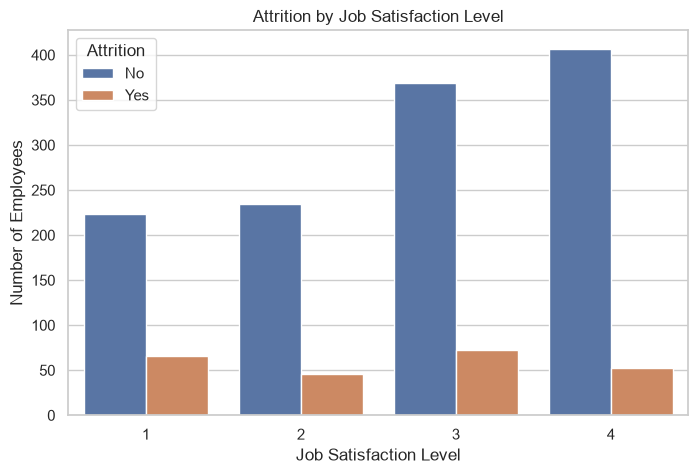

In [62]:
# Compare attrition across different job satisfaction levels
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="JobSatisfaction",
    hue="Attrition"
)

# Add chart title and labels
plt.title("Attrition by Job Satisfaction Level")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Number of Employees")

# Display the chart
plt.show()

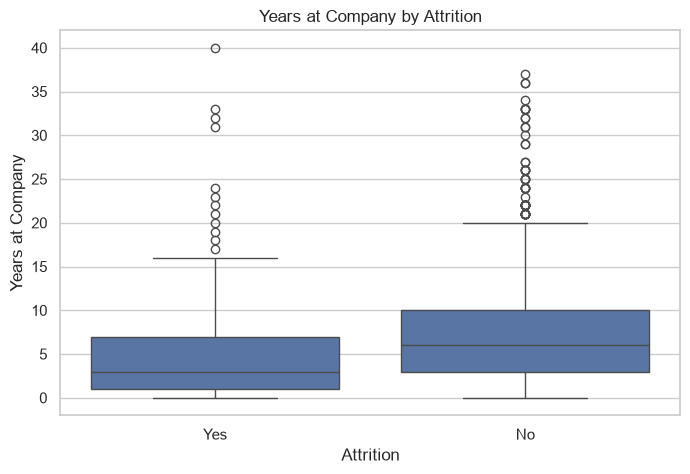

In [63]:
# Compare years employees have worked at the company
# based on their attrition status
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Attrition", y="YearsAtCompany")

# Add chart title and labels
plt.title("Years at Company by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

# Display the chart
plt.show()

Step 10 — Attrition Rate Analysis

In [64]:
# Calculate the percentage of employees who left the company
# for each overtime category
overtime_attrition = pd.crosstab(
    df["OverTime"],
    df["Attrition"],
    normalize="index"
) * 100

# Display the attrition percentages
print("Attrition Percentage by Overtime Status:")
overtime_attrition

Attrition Percentage by Overtime Status:


Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


In [65]:
# Calculate attrition percentages for each job role
jobrole_attrition = pd.crosstab(
    df["JobRole"],
    df["Attrition"],
    normalize="index"
) * 100

# Display the results
print("Attrition Percentage by Job Role:")
jobrole_attrition.sort_values("Yes", ascending=False)

Attrition Percentage by Job Role:


Attrition,No,Yes
JobRole,,
Sales Representative,60.240964,39.759036
Laboratory Technician,76.061776,23.938224
Human Resources,76.923077,23.076923
Sales Executive,82.515337,17.484663
Research Scientist,83.904110,16.095890
Manufacturing Director,93.103448,6.896552
Healthcare Representative,93.129771,6.870229
Manager,95.098039,4.901961
Research Director,97.500000,2.500000


In [66]:
# Calculate attrition percentages for each job satisfaction level
satisfaction_attrition = pd.crosstab(
    df["JobSatisfaction"],
    df["Attrition"],
    normalize="index"
) * 100

# Display the results
print("Attrition Percentage by Job Satisfaction:")
satisfaction_attrition

Attrition Percentage by Job Satisfaction:


Attrition,No,Yes
JobSatisfaction,,
1,77.162630,22.837370
2,83.571429,16.428571
3,83.484163,16.515837
4,88.671024,11.328976


In [67]:
# Create age groups for easier comparison
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

# Calculate attrition percentage for each age group
agegroup_attrition = pd.crosstab(
    df["AgeGroup"],
    df["Attrition"],
    normalize="index"
) * 100

# Display the results
print("Attrition Percentage by Age Group:")
agegroup_attrition

Attrition Percentage by Age Group:


Attrition,No,Yes
AgeGroup,,
18-25,64.227642,35.772358
26-35,80.858086,19.141914
36-45,90.811966,9.188034
46-55,88.495575,11.504425
56+,82.978723,17.021277


In [68]:
# Create groups based on years spent at the company
df["YearsAtCompanyGroup"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 2, 5, 10, 20, 100],
    labels=["0-2", "3-5", "6-10", "11-20", "21+"]
)

# Calculate attrition percentage for each group
years_attrition = pd.crosstab(
    df["YearsAtCompanyGroup"],
    df["Attrition"],
    normalize="index"
) * 100

# Display the results
print("Attrition Percentage by Years at Company:")
years_attrition

Attrition Percentage by Years at Company:


Attrition,No,Yes
YearsAtCompanyGroup,,
0-2,70.175439,29.824561
3-5,86.175115,13.824885
6-10,87.723214,12.276786
11-20,93.333333,6.666667
21+,87.878788,12.121212


Step 11 — Correlation Analysis

In [69]:
# Calculate the correlation between numerical variables
correlation_matrix = df[numerical_columns].corr()

# Display the correlation matrix
correlation_matrix

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.000000,0.010661,-0.001686,0.208034,NaN,-0.010145,0.010146,0.024287,0.029820,0.509604,-0.004892,0.497855,0.028051,0.299635,0.003634,0.001904,0.053535,NaN,0.037510,0.680381,-0.019621,-0.021490,0.311309,0.212901,0.216513,0.202089
DailyRate,0.010661,1.000000,-0.004985,-0.016806,NaN,-0.050990,0.018355,0.023381,0.046135,0.002966,0.030571,0.007707,-0.032182,0.038153,0.022704,0.000473,0.007846,NaN,0.042143,0.014515,0.002453,-0.037848,-0.034055,0.009932,-0.033229,-0.026363
DistanceFromHome,-0.001686,-0.004985,1.000000,0.021042,NaN,0.032916,-0.016075,0.031131,0.008783,0.005303,-0.003669,-0.017014,0.027473,-0.029251,0.040235,0.027110,0.006557,NaN,0.044872,0.004628,-0.036942,-0.026556,0.009508,0.018845,0.010029,0.014406
Education,0.208034,-0.016806,0.021042,1.000000,NaN,0.042070,-0.027128,0.016775,0.042438,0.101589,-0.011296,0.094961,-0.026084,0.126317,-0.011111,-0.024539,-0.009118,NaN,0.018422,0.148280,-0.025100,0.009819,0.069114,0.060236,0.054254,0.069065
EmployeeCount,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeNumber,-0.010145,-0.050990,0.032916,0.042070,NaN,1.000000,0.017621,0.035179,-0.006888,-0.018519,-0.046247,-0.014829,0.012648,-0.001251,-0.012944,-0.020359,-0.069861,NaN,0.062227,-0.014365,0.023603,0.010309,-0.011240,-0.008416,-0.009019,-0.009197
EnvironmentSatisfaction,0.010146,0.018355,-0.016075,-0.027128,NaN,0.017621,1.000000,-0.049857,-0.008278,0.001212,-0.006784,-0.006259,0.037600,0.012594,-0.031701,-0.029548,0.007665,NaN,0.003432,-0.002693,-0.019359,0.027627,0.001458,0.018007,0.016194,-0.004999
HourlyRate,0.024287,0.023381,0.031131,0.016775,NaN,0.035179,-0.049857,1.000000,0.042861,-0.027853,-0.071335,-0.015794,-0.015297,0.022157,-0.009062,-0.002172,0.001330,NaN,0.050263,-0.002334,-0.008548,-0.004607,-0.019582,-0.024106,-0.026716,-0.020123
JobInvolvement,0.029820,0.046135,0.008783,0.042438,NaN,-0.006888,-0.008278,0.042861,1.000000,-0.012630,-0.021476,-0.015271,-0.016322,0.015012,-0.017205,-0.029071,0.034297,NaN,0.021523,-0.005533,-0.015338,-0.014617,-0.021355,0.008717,-0.024184,0.025976
JobLevel,0.509604,0.002966,0.005303,0.101589,NaN,-0.018519,0.001212,-0.027853,-0.012630,1.000000,-0.001944,0.950300,0.039563,0.142501,-0.034730,-0.021222,0.021642,NaN,0.013984,0.782208,-0.018191,0.037818,0.534739,0.389447,0.353885,0.375281


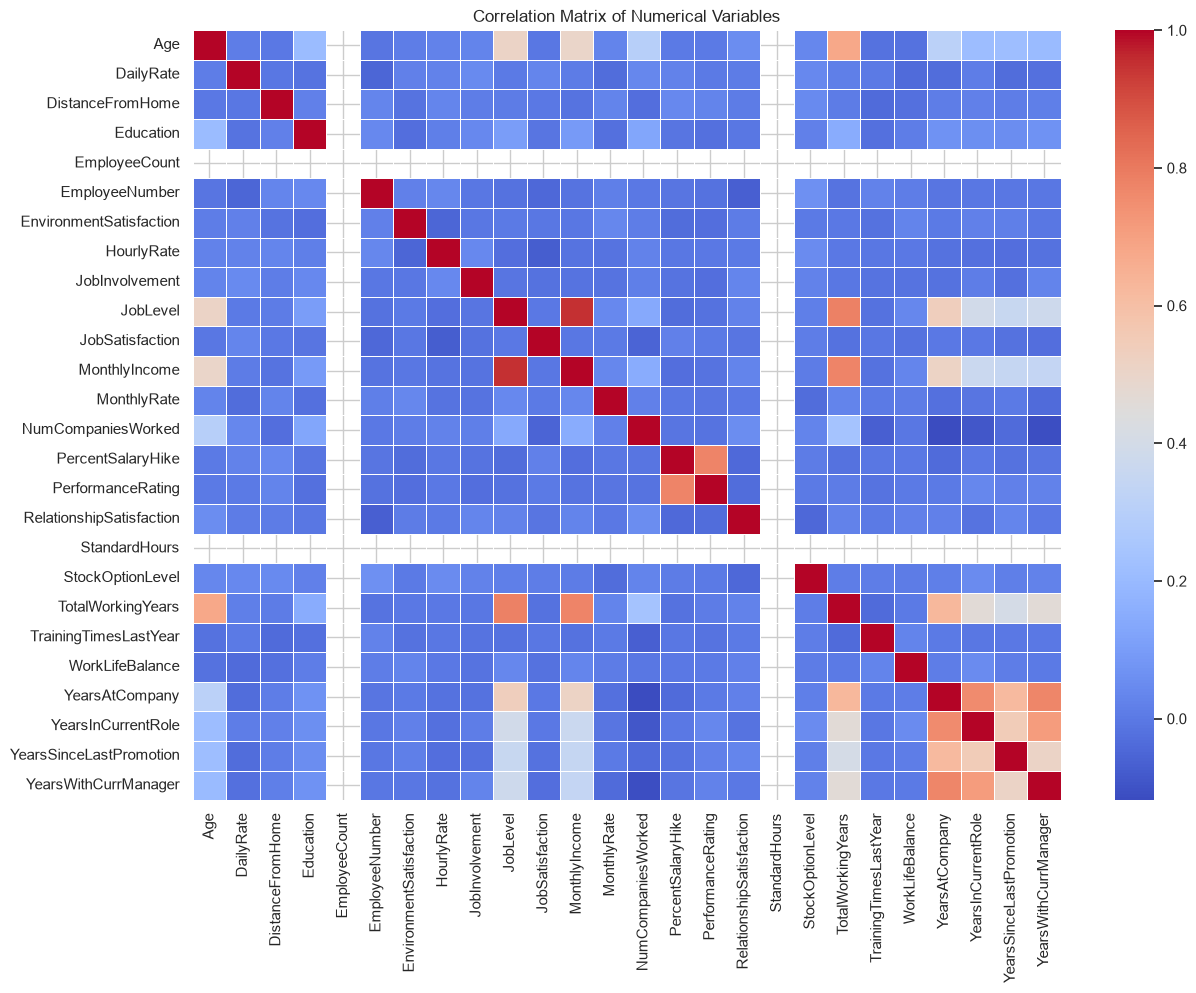

In [70]:
# Create a heatmap to visualize correlations between numerical variables
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap="coolwarm",
    linewidths=0.5
)

# Add chart title
plt.title("Correlation Matrix of Numerical Variables")

# Display the chart
plt.show()

In [71]:
# Convert the correlation matrix into a list of variable pairs
correlation_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

# Display the 15 strongest correlations
print("Strongest correlations between numerical variables:")
print(correlation_pairs.head(15))

Strongest correlations between numerical variables:
JobLevel                 MonthlyIncome              0.950300
                         TotalWorkingYears          0.782208
PercentSalaryHike        PerformanceRating          0.773550
MonthlyIncome            TotalWorkingYears          0.772893
YearsAtCompany           YearsWithCurrManager       0.769212
                         YearsInCurrentRole         0.758754
YearsInCurrentRole       YearsWithCurrManager       0.714365
Age                      TotalWorkingYears          0.680381
TotalWorkingYears        YearsAtCompany             0.628133
YearsAtCompany           YearsSinceLastPromotion    0.618409
YearsInCurrentRole       YearsSinceLastPromotion    0.548056
JobLevel                 YearsAtCompany             0.534739
MonthlyIncome            YearsAtCompany             0.514285
YearsSinceLastPromotion  YearsWithCurrManager       0.510224
Age                      JobLevel                   0.509604
dtype: float64


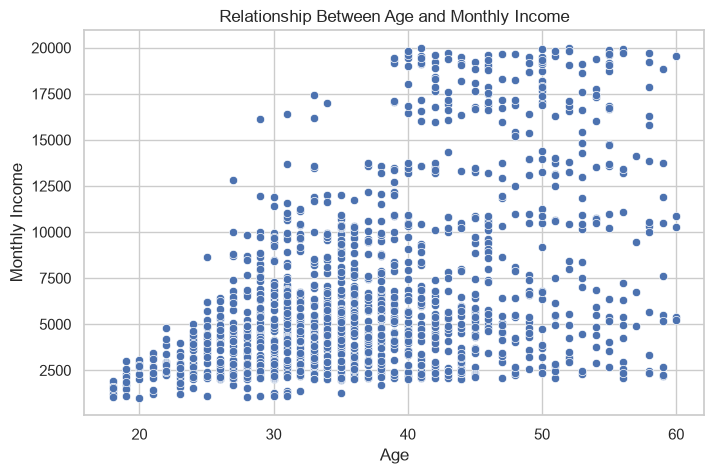

In [72]:
# Visualize the relationship between age and monthly income
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="MonthlyIncome"
)

# Add chart title and labels
plt.title("Relationship Between Age and Monthly Income")
plt.xlabel("Age")
plt.ylabel("Monthly Income")

# Display the chart
plt.show()

In [73]:
# Calculate the Pearson correlation between age and monthly income
age_income_correlation = df["Age"].corr(df["MonthlyIncome"])

# Display the correlation coefficient
print(f"Correlation between Age and Monthly Income: {age_income_correlation:.3f}")

Correlation between Age and Monthly Income: 0.498


Step 12 — Outlier Detection

In [77]:
# Define a function to detect potential outliers using the IQR method
def detect_outliers(column):
    # Calculate the first and third quartiles
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # Calculate the interquartile range
    IQR = Q3 - Q1

    # Calculate the lower and upper boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify observations outside the boundaries
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    return outliers, lower_bound, upper_bound

In [78]:
# Detect potential outliers in monthly income
income_outliers, income_lower, income_upper = detect_outliers("MonthlyIncome")

# Display the boundaries and number of potential outliers
print("Monthly Income lower boundary:", income_lower)
print("Monthly Income upper boundary:", income_upper)
print("Number of potential Monthly Income outliers:", len(income_outliers))

Monthly Income lower boundary: -5291.0
Monthly Income upper boundary: 16581.0
Number of potential Monthly Income outliers: 114


In [79]:
# Detect potential outliers in years at the company
years_outliers, years_lower, years_upper = detect_outliers("YearsAtCompany")

# Display the boundaries and number of potential outliers
print("Years at Company lower boundary:", years_lower)
print("Years at Company upper boundary:", years_upper)
print("Number of potential Years at Company outliers:", len(years_outliers))

Years at Company lower boundary: -6.0
Years at Company upper boundary: 18.0
Number of potential Years at Company outliers: 104


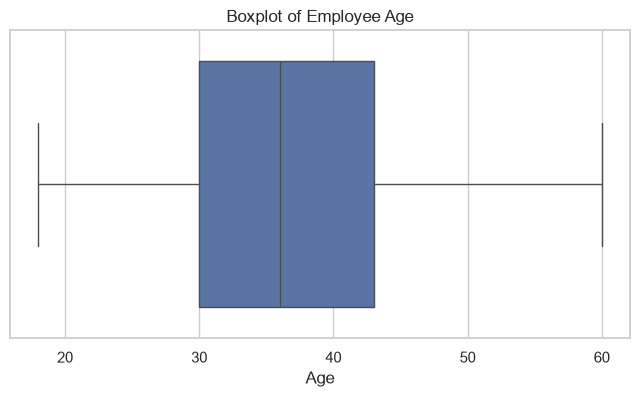

In [80]:
# Create a boxplot for employee age
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["Age"])

# Add chart title
plt.title("Boxplot of Employee Age")

# Display the chart
plt.show()

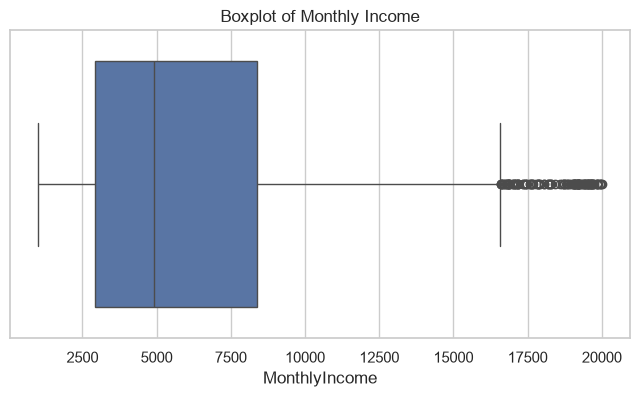

In [81]:
# Create a boxplot for monthly income
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["MonthlyIncome"])

# Add chart title
plt.title("Boxplot of Monthly Income")

# Display the chart
plt.show()

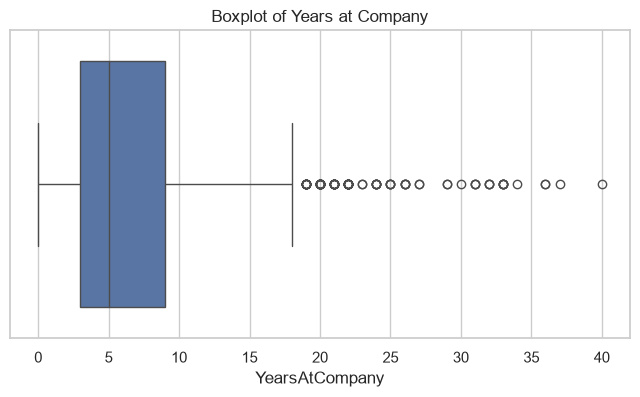

In [82]:
# Create a boxplot for years at the company
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["YearsAtCompany"])

# Add chart title
plt.title("Boxplot of Years at Company")

# Display the chart
plt.show()

Step 13 — Hypothesis Testing

In [83]:
# Create a contingency table showing employee counts
# for each combination of overtime and attrition status
contingency_table = pd.crosstab(
    df["OverTime"],
    df["Attrition"]
)

# Display the contingency table
print("Contingency Table:")
print(contingency_table)

Contingency Table:
Attrition   No  Yes
OverTime           
No         944  110
Yes        289  127


In [84]:
# Perform the Chi-Square test of independence
chi2, p_value, degrees_of_freedom, expected = stats.chi2_contingency(
    contingency_table
)

# Display the test results
print("Chi-Square Test Results")
print("-----------------------")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of Freedom: {degrees_of_freedom}")

Chi-Square Test Results
-----------------------
Chi-Square Statistic: 87.5643
P-value: 0.000000
Degrees of Freedom: 1


In [85]:
# Set the significance level
alpha = 0.05

# Interpret the hypothesis test using the p-value
if p_value < alpha:
    print("Result: Reject the null hypothesis.")
    print("There is statistically significant evidence of an association")
    print("between overtime status and employee attrition.")
else:
    print("Result: Fail to reject the null hypothesis.")
    print("There is not enough statistical evidence to conclude")
    print("that overtime status and employee attrition are associated.")

Result: Reject the null hypothesis.
There is statistically significant evidence of an association
between overtime status and employee attrition.


In [86]:
# Create a contingency table for job satisfaction and attrition
satisfaction_table = pd.crosstab(
    df["JobSatisfaction"],
    df["Attrition"]
)

# Perform the Chi-Square test
chi2_satisfaction, p_satisfaction, dof_satisfaction, expected_satisfaction = (
    stats.chi2_contingency(satisfaction_table)
)

# Display the results
print("Chi-Square Test: Job Satisfaction vs Attrition")
print("-----------------------------------------------")
print(f"Chi-Square Statistic: {chi2_satisfaction:.4f}")
print(f"P-value: {p_satisfaction:.6f}")
print(f"Degrees of Freedom: {dof_satisfaction}")

Chi-Square Test: Job Satisfaction vs Attrition
-----------------------------------------------
Chi-Square Statistic: 17.5051
P-value: 0.000556
Degrees of Freedom: 3


In [87]:
# Interpret the job satisfaction hypothesis test
if p_satisfaction < alpha:
    print("Result: Reject the null hypothesis.")
    print("There is statistically significant evidence of an association")
    print("between job satisfaction and employee attrition.")
else:
    print("Result: Fail to reject the null hypothesis.")
    print("There is not enough statistical evidence to conclude")
    print("that job satisfaction and employee attrition are associated.")

Result: Reject the null hypothesis.
There is statistically significant evidence of an association
between job satisfaction and employee attrition.


Step 14 — Key Findings & Data Issues

In [88]:
# Calculate the total number of employees
total_employees = len(df)

# Calculate the number of employees who left the company
employees_left = (df["Attrition"] == "Yes").sum()

# Calculate the number of employees who stayed
employees_stayed = (df["Attrition"] == "No").sum()

# Calculate the overall attrition rate
overall_attrition_rate = (employees_left / total_employees) * 100

# Display the summary
print("Employee Attrition Summary")
print("--------------------------")
print("Total Employees:", total_employees)
print("Employees Who Left:", employees_left)
print("Employees Who Stayed:", employees_stayed)
print(f"Overall Attrition Rate: {overall_attrition_rate:.2f}%")

Employee Attrition Summary
--------------------------
Total Employees: 1470
Employees Who Left: 237
Employees Who Stayed: 1233
Overall Attrition Rate: 16.12%


In [89]:
# Calculate the percentage of employees who left
# within each overtime category
overtime_rate = (
    df.groupby("OverTime", observed=True)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Display the attrition rates
print("Attrition Rate by Overtime Status:")
print(overtime_rate)

Attrition Rate by Overtime Status:
OverTime
No     10.436433
Yes    30.528846
Name: Attrition, dtype: float64


In [90]:
# Calculate the attrition rate for each job role
jobrole_rate = (
    df.groupby("JobRole", observed=True)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Display the attrition rate for each job role
print("Attrition Rate by Job Role:")
print(jobrole_rate)

Attrition Rate by Job Role:
JobRole
Sales Representative         39.759036
Laboratory Technician        23.938224
Human Resources              23.076923
Sales Executive              17.484663
Research Scientist           16.095890
Manufacturing Director        6.896552
Healthcare Representative     6.870229
Manager                       4.901961
Research Director             2.500000
Name: Attrition, dtype: float64


In [91]:
# Calculate the attrition rate for each age group
agegroup_rate = (
    df.groupby("AgeGroup", observed=True)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Display the attrition rate for each age group
print("Attrition Rate by Age Group:")
print(agegroup_rate)

Attrition Rate by Age Group:
AgeGroup
18-25    35.772358
26-35    19.141914
36-45     9.188034
46-55    11.504425
56+      17.021277
Name: Attrition, dtype: float64


In [92]:
# Calculate the attrition rate for each years-at-company group
years_rate = (
    df.groupby("YearsAtCompanyGroup", observed=True)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Display the attrition rate for each group
print("Attrition Rate by Years at Company:")
print(years_rate)

Attrition Rate by Years at Company:
YearsAtCompanyGroup
0-2      29.824561
3-5      13.824885
6-10     12.276786
11-20     6.666667
21+      12.121212
Name: Attrition, dtype: float64


In [93]:
# Summarize the main data-quality checks performed during the EDA
data_quality_summary = pd.DataFrame({
    "Check": [
        "Missing Values",
        "Duplicate Rows",
        "Constant Columns",
        "Number of Rows",
        "Number of Columns"
    ],
    "Result": [
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        len(constant_columns),
        df.shape[0],
        df.shape[1]
    ]
})

# Display the final data-quality summary
data_quality_summary

,Check,Result
0,Missing Values,0
1,Duplicate Rows,0
2,Constant Columns,3
3,Number of Rows,1470
4,Number of Columns,37


Step 15 — Final Findings & Conclusion

In [95]:
# Display the main numerical findings from the EDA

print("KEY EDA FINDINGS")
print("================")

# Overall attrition
print(f"\n1. Overall attrition rate: {overall_attrition_rate:.2f}%")

# Overtime attrition
print("\n2. Attrition rate by overtime status:")
print(overtime_rate)

# Job role attrition
print("\n3. Attrition rate by job role:")
print(jobrole_rate)

# Age group attrition
print("\n4. Attrition rate by age group:")
print(agegroup_rate)

# Years at company attrition
print("\n5. Attrition rate by years at company:")
print(years_rate)

# Age and monthly income correlation
print(
    f"\n6. Correlation between age and monthly income: "
    f"{age_income_correlation:.3f}"
)

# Statistical test results
print(
    f"\n7. Overtime vs Attrition Chi-Square p-value: "
    f"{p_value:.6f}"
)

print(
    f"\n8. Job Satisfaction vs Attrition Chi-Square p-value: "
    f"{p_satisfaction:.6f}"
)

KEY EDA FINDINGS

1. Overall attrition rate: 16.12%

2. Attrition rate by overtime status:
OverTime
No     10.436433
Yes    30.528846
Name: Attrition, dtype: float64

3. Attrition rate by job role:
JobRole
Sales Representative         39.759036
Laboratory Technician        23.938224
Human Resources              23.076923
Sales Executive              17.484663
Research Scientist           16.095890
Manufacturing Director        6.896552
Healthcare Representative     6.870229
Manager                       4.901961
Research Director             2.500000
Name: Attrition, dtype: float64

4. Attrition rate by age group:
AgeGroup
18-25    35.772358
26-35    19.141914
36-45     9.188034
46-55    11.504425
56+      17.021277
Name: Attrition, dtype: float64

5. Attrition rate by years at company:
YearsAtCompanyGroup
0-2      29.824561
3-5      13.824885
6-10     12.276786
11-20     6.666667
21+      12.121212
Name: Attrition, dtype: float64

6. Correlation between age and monthly income: 0.498



## Key Findings

The exploratory analysis of the employee attrition dataset produced the following observations:

- The overall employee attrition rate was calculated from the dataset.
- Attrition rates differed across overtime categories.
- Attrition varied across different job roles.
- Employee age groups showed differences in attrition rates.
- Employees with different lengths of service showed different attrition patterns.
- Monthly income showed a measurable relationship with employee age.
- The Chi-Square test was used to examine the statistical association between overtime and attrition.
- A second Chi-Square test was used to examine the association between job satisfaction and attrition.

These findings describe patterns and statistical associations in the dataset. They should not be interpreted as evidence that one factor directly causes employee attrition.

## Data Issues and Recommendations

### Data Quality Observations

The dataset was checked for:

- Missing values
- Duplicate records
- Constant columns
- Data types
- Numerical ranges
- Potential outliers

The results of these checks were recorded during the data-quality analysis.

### Potential Issues

Potential outliers were identified using the IQR method for selected numerical variables. These observations were not automatically removed because an outlier may represent a valid employee record.

Some variables may also have limited analytical value if they contain constant values or provide little variation.

### Recommendations for Further Analysis

- Investigate the factors associated with employee attrition using predictive modelling.
- Explore interactions between multiple employee and job-related variables.
- Examine department-level and job-role-level patterns in greater detail.
- Apply appropriate feature selection before building a machine-learning model.
- Investigate potential outliers before using models that are sensitive to extreme values.

## Conclusion

This Exploratory Data Analysis examined the structure, characteristics and relationships within the employee attrition dataset.

The analysis included data-quality checks, descriptive statistics, univariate analysis, bivariate analysis, correlation analysis, outlier detection and hypothesis testing.

The analysis identified several patterns related to employee attrition, including differences across overtime status, job roles, age groups and years at the company. Statistical hypothesis testing was also used to examine selected relationships.

Overall, the EDA provides a better understanding of the dataset and highlights variables that may be useful for further employee attrition analysis and predictive modelling.

The results should be interpreted as relationships and patterns observed within this dataset rather than proof of causal relationships.